# Retail demand panel: EDA, cleaning and data prep for iTransformer / ModernTCN

**Dataset:** `candidate_dataset.parquet`. A daily panel of 1,235 products over 732 days, with sales, stock, store availability, discount and price. Dates are in the **Jalali (Solar Hijri)** calendar.

**Goal:** understand the data, fix missing values and outliers, and export a dense, leakage-free `[time × products]` tensor. That is the input format multivariate long-horizon forecasters such as **iTransformer** and **ModernTCN** expect (Time-Series-Library conventions).

| # | Section |
|---|---------|
| 1 | Setup |
| 2 | Load data & convert Jalali dates |
| 3 | First look: schema, stats, product hierarchy |
| 4 | Data-quality audit: hidden missing values & corrupted dates |
| 5 | EDA: trend, calendar effects, distributions, drivers, autocorrelation |
| 6 | Handling missing values |
| 7 | Handling outliers |
| 8 | Model-ready data for iTransformer / ModernTCN |
| 9 | Summary |

## 1. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.tsa.stattools import acf

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# Works whether the notebook is run from the repo root or from notebooks/
DATA_PATH = next(p for p in [Path("candidate_dataset.parquet"), Path("../candidate_dataset.parquet")] if p.exists())
OUT_DIR = DATA_PATH.parent / "outputs"
OUT_DIR.mkdir(exist_ok=True)

# ---- cleaning parameters ----------------------------------------------------
ROLL_WINDOW = 29          # centred window (days) for robust local baselines
HAMPEL_K = 6.0            # robust z-score threshold for sales spikes
MIN_SPIKE_MULT = 3.0      # ...and the spike must be >= 3x the expected value
PROMO_PP = 5.0            # a discount jump of > 5 pp "explains" a spike (kept)
PRICE_BOUNDS = (0.5, 2.0) # realised price outside [0.5x, 2x] of local median -> outlier

# ---- modelling parameters (Time-Series-Library defaults) --------------------
SPLIT = (0.7, 0.1, 0.2)   # chronological train / val / test
SEQ_LEN, LABEL_LEN, PRED_LEN = 96, 48, 28

# ---- plotting style: validated categorical palette, hairline grids ----------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 1.5,
    "legend.frameon": False, "figure.dpi": 100, "font.size": 10, "figure.figsize": (12, 4),
})
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
C_BLUE, C_ORANGE, C_AQUA, C_RED = PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[7]

## 2. Load data & convert Jalali dates

`date` is stored as a Jalali string such as `14030631` (= 1403/06/31). Converting it to Gregorian gives a proper `datetime` axis for resampling, plotting and the model's time features. We keep the Jalali year/month/day too, because Iranian seasonality (Nowruz, Esfand shopping) follows the Jalali calendar.

In [2]:
def jalali_to_gregorian(jy: int, jm: int, jd: int) -> tuple[int, int, int]:
    # Exact arithmetic Jalali -> Gregorian conversion (jalaali algorithm, valid 1-3177 AP).
    jy += 1595
    days = -355668 + 365 * jy + (jy // 33) * 8 + ((jy % 33) + 3) // 4 + jd
    days += (jm - 1) * 31 if jm < 7 else (jm - 7) * 30 + 186
    gy = 400 * (days // 146097)
    days %= 146097
    if days > 36524:
        days -= 1
        gy += 100 * (days // 36524)
        days %= 36524
        if days >= 365:
            days += 1
    gy += 4 * (days // 1461)
    days %= 1461
    if days > 365:
        gy += (days - 1) // 365
        days = (days - 1) % 365
    gd = days + 1
    leap = (gy % 4 == 0 and gy % 100 != 0) or gy % 400 == 0
    month_days = [31, 29 if leap else 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
    gm = 0
    while gd > month_days[gm]:
        gd -= month_days[gm]
        gm += 1
    return gy, gm + 1, gd

# sanity anchors: Nowruz always falls on 20/21 March
assert jalali_to_gregorian(1404, 1, 1) == (2025, 3, 21)
assert jalali_to_gregorian(1405, 1, 1) == (2026, 3, 21)
assert jalali_to_gregorian(1403, 6, 31) == (2024, 9, 21)

In [3]:
raw = pd.read_parquet(DATA_PATH)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns | {raw.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")

NUM = ["sale_qty", "stock_qty", "num_stores_with_stock", "discount_pct", "price"]
STATIC = ["brand_id", "Level1", "Level2", "Level3", "Level4", "Level5"]

df = raw.copy()
df[NUM] = df[NUM].astype("float64")             # pyarrow-backed -> numpy for speed
for c in ["date", "product_id"] + STATIC:
    df[c] = df[c].astype(str)

# calendar table: one row per Jalali date
cal = pd.DataFrame({"jdate": np.sort(df["date"].unique())})
cal["j_year"] = cal.jdate.str[:4].astype(int)
cal["j_month"] = cal.jdate.str[4:6].astype(int)
cal["j_day"] = cal.jdate.str[6:8].astype(int)
cal["ds"] = [pd.Timestamp(*jalali_to_gregorian(y, m, d)) for y, m, d in zip(cal.j_year, cal.j_month, cal.j_day)]

# the Jalali dates must map to a gap-free run of Gregorian days
assert cal.ds.is_monotonic_increasing and (cal.ds.diff().dropna() == pd.Timedelta(days=1)).all()
print(f"Calendar: {cal.jdate.iloc[0]} -> {cal.jdate.iloc[-1]}  =  {cal.ds.iloc[0].date()} -> {cal.ds.iloc[-1].date()}  ({len(cal)} consecutive days)")

df = df.merge(cal[["jdate", "ds"]], left_on="date", right_on="jdate").drop(columns="jdate")
df = df.sort_values(["product_id", "ds"], ignore_index=True)
df.head()

902,438 rows x 13 columns | 139 MB in memory
Calendar: 14030631 -> 14050631  =  2024-09-21 -> 2026-09-22  (732 consecutive days)


,date,product_id,brand_id,Level1,Level2,Level3,Level4,Level5,sale_qty,stock_qty,num_stores_with_stock,discount_pct,price,ds
0,14030631,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,3784.50,110840.02,277.0,19.2,434667.0,2024-09-21
1,14030701,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,2840.05,109396.02,277.0,19.2,433960.0,2024-09-22
2,14030702,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,2448.67,109004.64,277.0,22.3,434770.0,2024-09-23
3,14030703,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,2099.65,107033.22,276.0,18.5,433362.0,2024-09-24
4,14030704,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,1436.19,105016.08,276.0,19.0,435390.0,2024-09-25


## 3. First look: schema, statistics, product hierarchy

In [4]:
print(df.dtypes.to_string(), "\n")
print("Unique values:\n" + df[["product_id"] + STATIC].nunique().to_string(), "\n")
df[NUM].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2)

date                                str
product_id                          str
brand_id                            str
Level1                              str
Level2                              str
Level3                              str
Level4                              str
Level5                              str
sale_qty                        float64
stock_qty                       float64
num_stores_with_stock           float64
discount_pct                    float64
price                           float64
ds                       datetime64[us] 

Unique values:
product_id    1235
brand_id       234
Level1           5
Level2          25
Level3          49
Level4          88
Level5         289 



,count,mean,std,min,1%,25%,50%,75%,99%,max
sale_qty,902438.0,766.21,1955.69,0.0,0.00,76.79,247.06,716.91,8163.34,129289.62
stock_qty,902438.0,17094.03,30930.74,0.6,18.24,3396.49,8505.76,18981.33,138572.00,943410.64
num_stores_with_stock,902438.0,209.00,101.44,0.0,2.00,136.00,237.00,286.00,366.00,386.00
discount_pct,902438.0,9.87,8.16,0.0,0.00,2.80,8.70,14.80,35.00,82.20
price,902438.0,1636460.12,2081929.91,0.0,0.00,441220.00,908701.50,2003155.00,10385669.40,22887391.00


Fully duplicated rows      : 0
Duplicated (product, date) : 0
Negative values            : {'sale_qty': 0, 'stock_qty': 0, 'num_stores_with_stock': 0, 'discount_pct': 0, 'price': 0}


Products with >1 brand/level value: 0
  Level2 nodes with >1 Level1 parent: 0
  Level3 nodes with >1 Level2 parent: 0
  Level4 nodes with >1 Level3 parent: 0
  Level5 nodes with >1 Level4 parent: 0


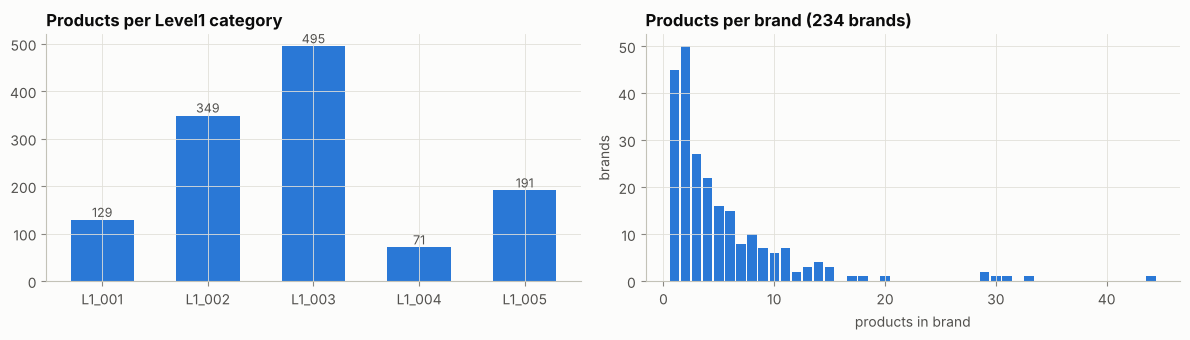

In [5]:
print("Fully duplicated rows      :", df.duplicated().sum())
print("Duplicated (product, date) :", df.duplicated(["product_id", "ds"]).sum())
print("Negative values            :", (df[NUM] < 0).sum().to_dict())

# Is the product -> brand -> Level1..5 hierarchy a clean tree?
print("Products with >1 brand/level value:", int((df.groupby("product_id")[STATIC].nunique() > 1).sum().sum()))
levels = ["Level1", "Level2", "Level3", "Level4", "Level5"]
for parent, child in zip(levels[:-1], levels[1:]):
    print(f"  {child} nodes with >1 {parent} parent: {(df.groupby(child)[parent].nunique() > 1).sum()}")

meta = df.groupby("product_id")[STATIC].first()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
cnt = meta.Level1.value_counts().sort_index()
axes[0].bar(cnt.index, cnt.values, color=C_BLUE, width=0.6)
axes[0].set_title("Products per Level1 category")
for x, v in zip(cnt.index, cnt.values):
    axes[0].text(x, v, f"{v}", ha="center", va="bottom", color=INK2, fontsize=9)
bpp = meta.brand_id.value_counts()
axes[1].hist(bpp, bins=np.arange(0.5, bpp.max() + 1.5), color=C_BLUE, rwidth=0.85)
axes[1].set_title(f"Products per brand ({meta.brand_id.nunique()} brands)")
axes[1].set_xlabel("products in brand"); axes[1].set_ylabel("brands")
plt.tight_layout(); plt.show()

**Takeaways**
- There are no NaNs, no duplicate keys and no negative values. The hierarchy is a clean tree (product → brand, product → L1 → … → L5). It can be used later for hierarchical reconciliation or as static covariates.
- That does **not** mean the data is complete. Section 4 shows that the missing values are hidden.

## 4. Data-quality audit: hidden missing values & corrupted dates

### 4.1 Missing rows (implicit missing values)
A full panel would have 1,235 × 732 = 904,020 rows, but the file has fewer. We build the complete daily grid inside each product's own lifespan (first to last observed day) and see which rows are absent.

Rows expected in lifespans : 903,937
Rows present               : 902,438
Missing rows               : 1,499 (0.17%) across 309 products
Products starting late     : 1  -> ['P_0071']
Products ending early      : 2  -> ['P_0906', 'P_1214']

Gap length (days) distribution:
 count    525.0
mean       2.9
std        6.1
min        1.0
25%        1.0
50%        1.0
75%        1.0
max       64.0


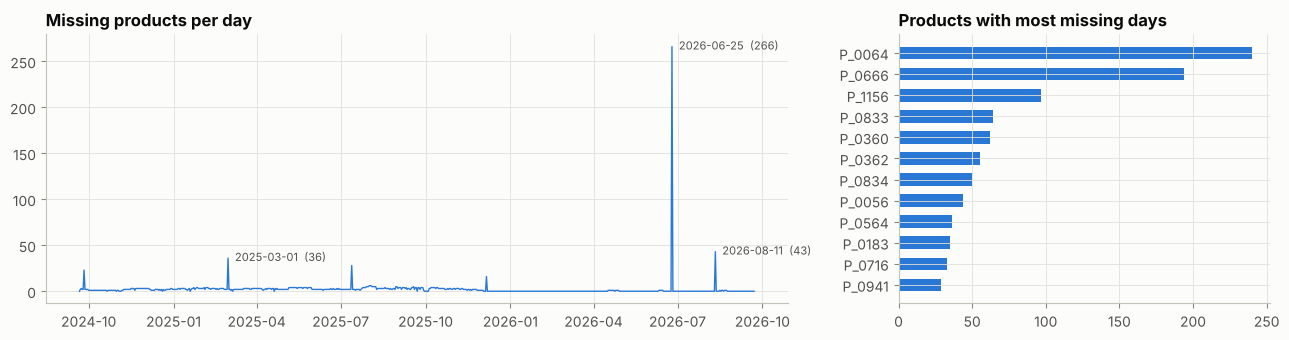

In [6]:
life = df.groupby("product_id")["ds"].agg(start="min", end="max")
grid = pd.DataFrame({
    "product_id": np.repeat(life.index.values, ((life.end - life.start).dt.days + 1).values),
    "ds": np.concatenate([pd.date_range(s, e).values for s, e in zip(life.start, life.end)]),
})
full = (grid.merge(df.drop(columns=STATIC + ["date"]), on=["product_id", "ds"], how="left")
            .merge(meta, left_on="product_id", right_index=True)
            .sort_values(["product_id", "ds"], ignore_index=True))
full["is_missing_row"] = full["sale_qty"].isna()

print(f"Rows expected in lifespans : {len(full):,}")
print(f"Rows present               : {len(df):,}")
print(f"Missing rows               : {full.is_missing_row.sum():,} ({full.is_missing_row.mean():.2%}) "
      f"across {full.loc[full.is_missing_row, 'product_id'].nunique()} products")
print(f"Products starting late     : {(life.start > cal.ds.min()).sum()}  -> {list(life.index[life.start > cal.ds.min()])}")
print(f"Products ending early      : {(life.end < cal.ds.max()).sum()}  -> {list(life.index[life.end < cal.ds.max()])}")

# gap run lengths
run_id = (full.is_missing_row != full.is_missing_row.shift()).cumsum()
runs = full[full.is_missing_row].groupby(run_id).size()
print("\nGap length (days) distribution:\n", runs.describe().round(1).to_string())

per_date = full.groupby("ds").is_missing_row.sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(per_date.index, per_date.values, color=C_BLUE, lw=1)
axes[0].set_title("Missing products per day")
for d, v in per_date.nlargest(3).items():
    axes[0].annotate(f"{d.date()}  ({v})", (d, v), xytext=(5, -2), textcoords="offset points", fontsize=8, color=INK2)
per_prod = full.groupby("product_id").is_missing_row.sum().sort_values(ascending=False).head(12)
axes[1].barh(per_prod.index[::-1], per_prod.values[::-1], color=C_BLUE, height=0.6)
axes[1].set_title("Products with most missing days")
plt.tight_layout(); plt.show()

**What does a missing row mean?** If rows go missing when a product has no activity, the right fill is `sale_qty = 0`, not interpolation. To check, look at the product's availability on the last observed day **before** each gap:

In [7]:
prev_stores = full.groupby("product_id")["num_stores_with_stock"].ffill()   # value carried into the gap
prev_sales = full.groupby("product_id")["sale_qty"].ffill()
cmp = pd.DataFrame({
    "stores with stock (median)": [prev_stores[full.is_missing_row].median(), full.num_stores_with_stock.median()],
    "share <= 5 stores": [(prev_stores[full.is_missing_row] <= 5).mean(), (full.num_stores_with_stock <= 5).mean()],
    "sale_qty (median)": [prev_sales[full.is_missing_row].median(), full.sale_qty.median()],
}, index=["day before a gap", "all observed rows"])
cmp.round(3)

,stores with stock (median),share <= 5 stores,sale_qty (median)
day before a gap,0.0,0.826,0.80
all observed rows,237.0,0.028,247.06


Gaps follow near-stockouts: the median product is in **0 stores** the day before a gap, versus about 237 stores normally. So a missing row means the product was effectively unavailable and sold nothing. **Imputation rule: `sale_qty = 0`, with a flag** (Section 6).

### 4.2 Disguised missing values: `price == 0`

In [8]:
print(pd.crosstab(df.sale_qty == 0, df.price == 0, rownames=["sale_qty == 0"], colnames=["price == 0"]))

price == 0      False  True 
sale_qty == 0               
False          879481      0
True                0  22957


`price == 0` occurs **exactly** when `sale_qty == 0`. So `price` is the *realised* average selling price (revenue / units). It is undefined, not zero, on days without sales. **Treatment: set it to NaN and impute it from neighbouring days.**

### 4.3 Corrupted dates: `stock_qty` overwritten by `sale_qty`
On some dates almost every product reports `stock_qty == sale_qty`, and `num_stores_with_stock` collapses at the same time. This is a system-level ETL fault, not real behaviour. We detect these dates automatically.

Detected 6 corrupted dates:


,share_stock_eq_sale,median_store_ratio,products_reported,glitch,jdate
ds,,,,,
2024-09-26,1.000,0.402,1211,True,14030705
2025-03-01,1.000,0.354,1199,True,14031211
2025-07-13,0.243,0.299,1207,True,14040422
2025-12-06,1.000,0.306,1219,True,14040915
2026-06-25,1.000,0.008,969,True,14050404
2026-08-11,1.000,0.292,1192,True,14050520


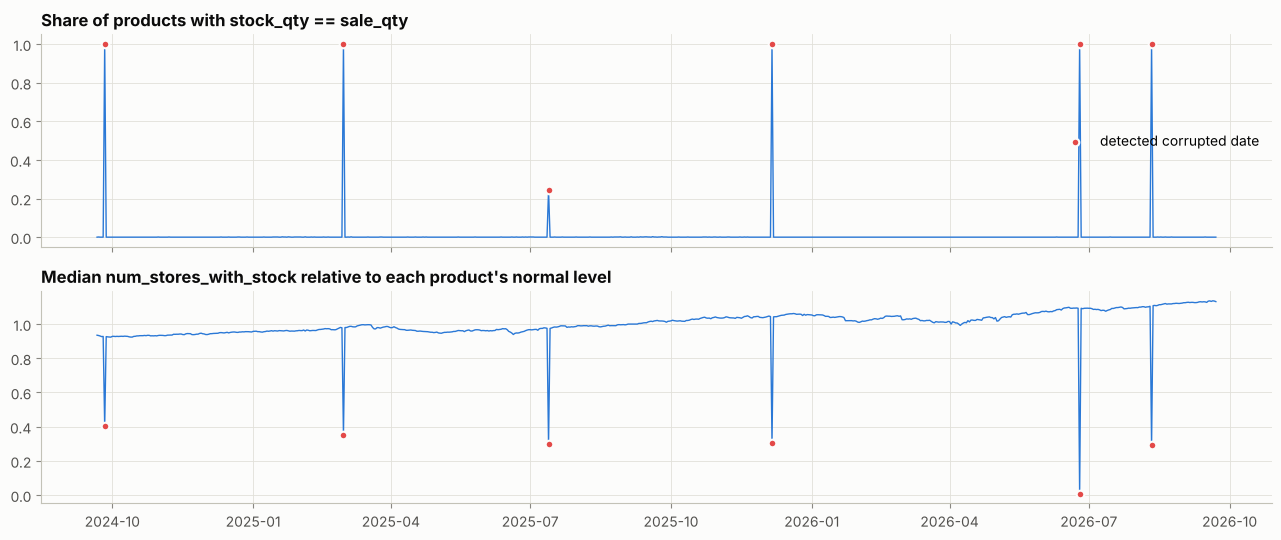

In [9]:
obs = full[~full.is_missing_row].copy()
obs["stock_eq_sale"] = np.isclose(obs.stock_qty, obs.sale_qty)
obs["store_ratio"] = obs.num_stores_with_stock / obs.groupby("product_id").num_stores_with_stock.transform("median").replace(0, np.nan)
daily_q = obs.groupby("ds").agg(share_stock_eq_sale=("stock_eq_sale", "mean"),
                                median_store_ratio=("store_ratio", "median"),
                                products_reported=("product_id", "size"))
daily_q["glitch"] = (daily_q.share_stock_eq_sale > 0.10) | (daily_q.median_store_ratio < 0.60)
GLITCH_DATES = daily_q.index[daily_q.glitch]
print(f"Detected {len(GLITCH_DATES)} corrupted dates:")
display(daily_q[daily_q.glitch].round(3).assign(jdate=cal.set_index("ds").loc[GLITCH_DATES, "jdate"].values))

fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
axes[0].plot(daily_q.index, daily_q.share_stock_eq_sale, color=C_BLUE, lw=1)
axes[0].set_title("Share of products with stock_qty == sale_qty")
axes[1].plot(daily_q.index, daily_q.median_store_ratio, color=C_BLUE, lw=1)
axes[1].set_title("Median num_stores_with_stock relative to each product's normal level")
for ax in axes:
    ax.scatter(GLITCH_DATES, daily_q.loc[GLITCH_DATES, "share_stock_eq_sale" if ax is axes[0] else "median_store_ratio"],
               color=C_RED, s=30, zorder=3, label="detected corrupted date", edgecolor=SURFACE, linewidth=1.5)
axes[0].legend(loc="center right")
plt.tight_layout(); plt.show()

In [10]:
# Are sales and price also affected on those days? Compare with a centred 15-day rolling median.
def local_ratio(col):
    med = obs.groupby("product_id")[col].transform(lambda s: s.rolling(15, center=True, min_periods=5).median())
    return (obs[col] / med.replace(0, np.nan)).groupby(obs.ds).median()

check = pd.DataFrame({c: local_ratio(c) for c in ["sale_qty", "price", "discount_pct", "stock_qty", "num_stores_with_stock"]})
check.loc[GLITCH_DATES].round(3).assign(weekday=GLITCH_DATES.day_name().str[:3])

,sale_qty,price,discount_pct,stock_qty,num_stores_with_stock,weekday
ds,,,,,,
2024-09-26,1.260,1.000,1.00,0.041,0.410,Thu
2025-03-01,1.000,1.000,1.00,0.031,0.356,Sat
2025-07-13,1.016,0.999,0.98,0.224,0.304,Sun
2025-12-06,0.964,1.000,1.00,0.025,0.298,Sat
2026-06-25,0.018,1.002,0.85,0.001,0.007,Thu
2026-08-11,1.032,1.000,1.00,0.026,0.261,Tue


- On corrupted dates **stock and store counts** are wrong: stock falls to about 3% and store count to about 30% of normal. **Sales, price and discount are fine.** (Higher sales on Thursdays, such as 2024-09-26, is the normal weekly peak; see 5.2.)
- **2026-06-25 is a special case.** It is **Ashura** (4 Tir 1405), a public holiday when shops close. Its very low sales are *real* (Ashura 2025, on 2025-07-06, looks the same), but its stock and store counts are corrupted, and 266 products are missing that day:

In [11]:
ashura_25, ashura_26 = full[full.ds == "2025-07-06"], full[full.ds == "2026-06-25"]
miss_26 = ashura_26.loc[ashura_26.is_missing_row, "product_id"]
avg_sales = df.groupby("product_id").sale_qty.mean()
print(f"Ashura 2025: share of reported rows with sale_qty == 0 : {(ashura_25.sale_qty == 0).mean():.1%}")
print(f"Ashura 2026: share of reported rows with sale_qty == 0 : {(ashura_26.sale_qty == 0).mean():.1%}  (zero-sale rows were not written)")
print(f"Ashura 2026: products missing                         : {len(miss_26)}")
print(f"Mean daily sales of the missing products vs present   : {avg_sales[miss_26].median():.0f} vs {avg_sales.drop(miss_26).median():.0f}")
print(f"Same products on Ashura 2025 with zero sales          : {(ashura_25.set_index('product_id').sale_qty.reindex(miss_26) == 0).mean():.0%}")

Ashura 2025: share of reported rows with sale_qty == 0 : 41.2%
Ashura 2026: share of reported rows with sale_qty == 0 : 0.0%  (zero-sale rows were not written)
Ashura 2026: products missing                         : 266
Mean daily sales of the missing products vs present   : 82 vs 397
Same products on Ashura 2025 with zero sales          : 67%


On Ashura 2026 the pipeline dropped rows with zero sales. The 266 missing products are low-volume ones, and most of them also sold nothing on Ashura 2025. So the same rule applies: **missing row → `sale_qty = 0`**.

**Treatment for corrupted dates (Section 6):** set `stock_qty` and `num_stores_with_stock` to NaN on these dates and interpolate within each product. Keep sales, price and discount.

## 5. Exploratory data analysis

### 5.1 Aggregate sales over time

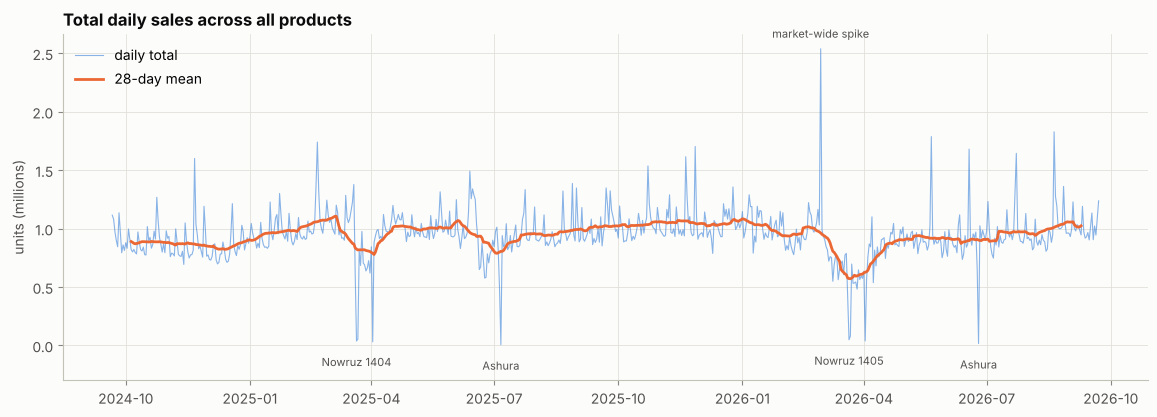

ds             2024-09  2024-10  2024-11  2024-12  2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10  2025-11  2025-12  2026-01  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07  2026-08  2026-09
k units / day      947      887      875      831      967     1038      890      971     1005      947      901      961     1012     1031     1059     1033     1034     1005      644      822      922      889      972      992     1016


In [12]:
total = df.groupby("ds").sale_qty.sum()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(total.index, total.values / 1e6, color=C_BLUE, lw=0.8, alpha=0.55, label="daily total")
ax.plot(total.index, total.rolling(28, center=True).mean() / 1e6, color=C_ORANGE, lw=2, label="28-day mean")
ax.set_ylabel("units (millions)")
ax.set_ylim(-0.3, None)
ax.set_title("Total daily sales across all products")
events = {"2025-03-21": "Nowruz 1404", "2025-07-06": "Ashura", "2026-03-21": "Nowruz 1405",
          "2026-06-25": "Ashura", "2026-02-28": "market-wide spike"}
for d, label in events.items():
    d = pd.Timestamp(d)
    ax.annotate(label, (d, total[d] / 1e6), xytext=(0, -18 if total[d] < 3e5 else 8), textcoords="offset points",
                ha="center", fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="upper left")
plt.show()

monthly = df.groupby(df.ds.dt.to_period("M")).agg(units=("sale_qty", "sum"), days=("ds", "nunique"))
monthly["units_per_day"] = monthly.units / monthly.days
print((monthly.units_per_day / 1e3).round(0).astype(int).to_frame("k units / day").T.to_string())

- Daily volume is fairly stable at roughly 0.8–1.1M units. There is a clear **dip in Mar–Apr 2026** (Nowruz plus a broader slowdown) and a recovery by the summer.
- **Extremely deep one-day drops** fall on **Nowruz, Sizdah Bedar (13 Farvardin) and Tasua/Ashura**. These are real closures, *not* outliers, so they must be modelled with calendar features, not smoothed away.

### 5.2 Calendar effects: day of week and market-wide event days
To separate calendar effects from product noise we compute a **market effect** for each day. It is the median, across products, of `log1p(sales) − product's 29-day centred rolling median`, and it shows how far the whole market moved that day.

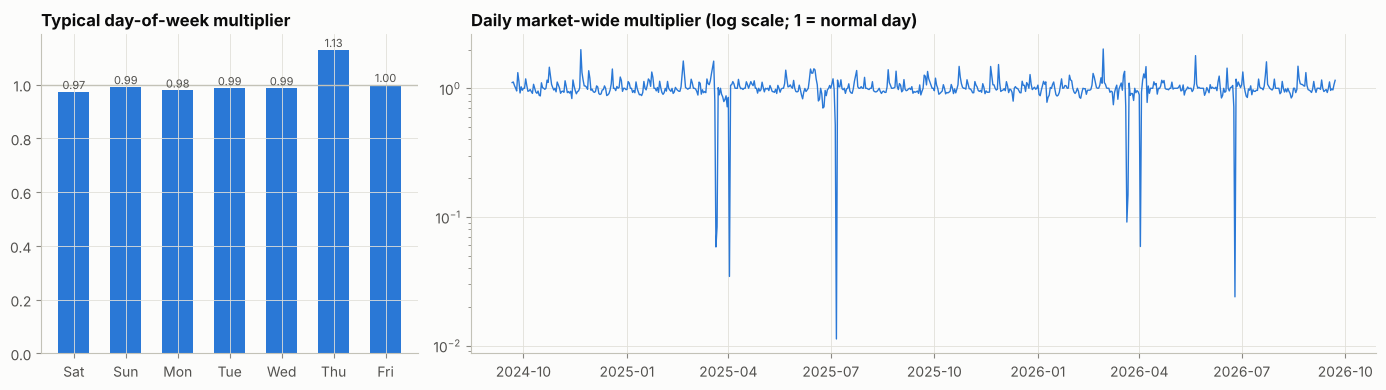

Strongest market-wide DROPS


,multiplier,weekday,jdate
ds,,,
2025-07-06,0.011,Sun,14040415
2026-06-25,0.024,Thu,14050404
2025-04-02,0.034,Wed,14040113
2025-03-21,0.058,Fri,14040101
2026-04-02,0.059,Thu,14050113
2025-03-22,0.084,Sat,14040102
2026-03-21,0.091,Sat,14050101
2026-03-22,0.148,Sun,14050102
2025-07-05,0.516,Sat,14040414


Strongest market-wide SURGES


,multiplier,weekday,jdate
ds,,,
2026-02-28,2.020,Sat,14041209
2024-11-21,1.997,Thu,14030901
2026-05-21,1.794,Thu,14050231
2025-02-20,1.630,Thu,14031202
2025-03-19,1.626,Wed,14031229
2026-07-23,1.606,Thu,14050501
2025-11-27,1.530,Thu,14040906
2026-08-20,1.485,Thu,14050529


In [13]:
def robust_deviation(frame, value_col="sale_qty", group_col="Level1", window=ROLL_WINDOW):
    # log1p(value) minus a product-level centred rolling median; plus the day x group median of that residual.
    y = np.log1p(frame[value_col])
    base = y.groupby(frame["product_id"]).transform(
        lambda s: s.rolling(window, center=True, min_periods=window // 2).median())
    resid = y - base
    market = resid.groupby([frame["ds"], frame[group_col]]).transform("median")
    return y, base, resid, market

tmp = full.assign(sale_qty=full.sale_qty.fillna(0))       # missing rows = 0 (see 4.1)
_, _, resid_eda, _ = robust_deviation(tmp)
market_daily = resid_eda.groupby(tmp.ds).median()
mult = np.exp(market_daily)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2.4]})
dow_order = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]   # Iranian week
dow = mult[~mult.index.isin(GLITCH_DATES)].groupby(mult.index[~mult.index.isin(GLITCH_DATES)].day_name()).median().reindex(dow_order)
axes[0].bar([d[:3] for d in dow.index], dow.values, color=C_BLUE, width=0.6)
axes[0].axhline(1, color=AXIS, lw=1)
axes[0].set_title("Typical day-of-week multiplier")
for i, v in enumerate(dow.values):
    axes[0].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color=INK2)
axes[1].plot(mult.index, mult.values, color=C_BLUE, lw=1)
axes[1].set_yscale("log")
axes[1].set_title("Daily market-wide multiplier (log scale; 1 = normal day)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

ev = pd.DataFrame({"multiplier": mult.round(3), "weekday": mult.index.day_name().str[:3],
                   "jdate": cal.set_index("ds").loc[mult.index, "jdate"].values})
print("Strongest market-wide DROPS"); display(ev.nsmallest(10, "multiplier"))
print("Strongest market-wide SURGES"); display(ev.nlargest(8, "multiplier"))

- **Thursday is the weekly peak** (start of the Iranian weekend). Friday is not a trough, so the week has its own pattern and needs a day-of-week feature.
- The deepest drops map exactly to **Nowruz (1–2 Farvardin), Sizdah Bedar (13 Farvardin) and Tasua/Ashura**, where sales fall to 1–15% of normal. The last days of Esfand show the **pre-Nowruz shopping peak**.
- The surges are mostly Thursdays, plus **2026-02-28**, a broad market-wide spike (the median product sold about 2×). This is real and shared across products, so it is *not* treated as an outlier.
- **Decision:** calendar extremes are kept and encoded as features (Section 8). Outlier detection (Section 7) works on residuals **after removing this market effect**, so holidays are never "cleaned".

### 5.3 Distribution of sales across products

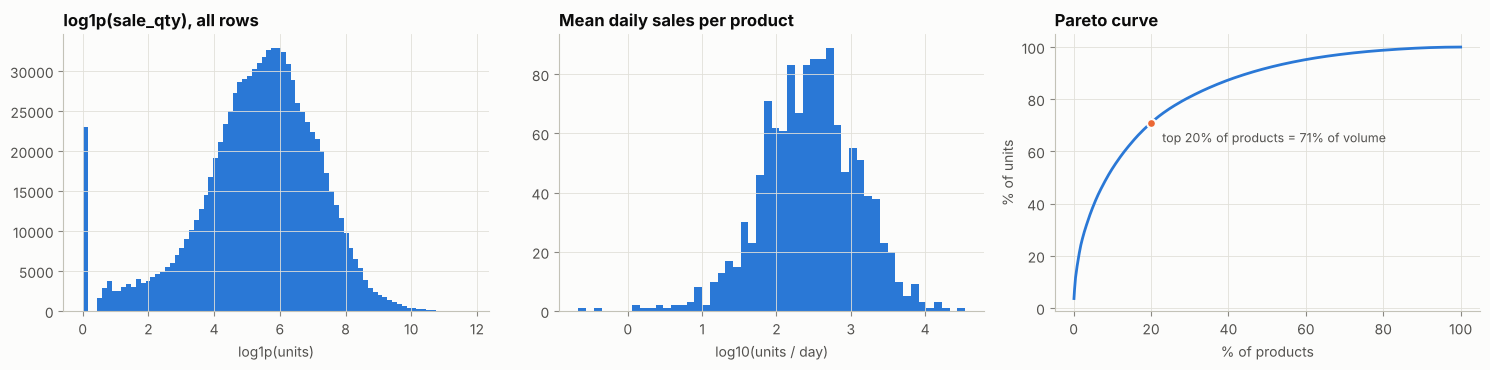

Zero-sales rows: 2.54% | skewness of sale_qty: 11.3 | product mean sales range: 0.22 .. 34,351


In [14]:
tot_by_prod = df.groupby("product_id").sale_qty.sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(np.log1p(df.sale_qty), bins=80, color=C_BLUE)
axes[0].set_title("log1p(sale_qty), all rows"); axes[0].set_xlabel("log1p(units)")
axes[1].hist(np.log10(df.groupby("product_id").sale_qty.mean()), bins=50, color=C_BLUE)
axes[1].set_title("Mean daily sales per product"); axes[1].set_xlabel("log10(units / day)")
cum = tot_by_prod.cumsum() / tot_by_prod.sum()
axes[2].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color=C_BLUE, lw=2)
k20 = cum.iloc[int(0.2 * len(cum)) - 1] * 100
axes[2].scatter([20], [k20], color=C_ORANGE, zorder=3, s=40, edgecolor=SURFACE, linewidth=1.5)
axes[2].annotate(f"top 20% of products = {k20:.0f}% of volume", (20, k20), xytext=(8, -14), textcoords="offset points", fontsize=9, color=INK2)
axes[2].set_title("Pareto curve"); axes[2].set_xlabel("% of products"); axes[2].set_ylabel("% of units")
plt.tight_layout(); plt.show()
print(f"Zero-sales rows: {(df.sale_qty == 0).mean():.2%} | skewness of sale_qty: {df.sale_qty.skew():.1f} | "
      f"product mean sales range: {df.groupby('product_id').sale_qty.mean().min():.2f} .. {df.groupby('product_id').sale_qty.mean().max():,.0f}")

- Sales are **heavily right-skewed**, and product scales span about **5 orders of magnitude**. Neural forecasters need a **`log1p` transform plus per-series (per-channel) standardisation**. Otherwise a handful of high-volume products dominate the loss.

### 5.4 Demand patterns: ADI / CV² classification (Syntetos–Boylan)

class
smooth          857
erratic         343
lumpy            31
intermittent      4


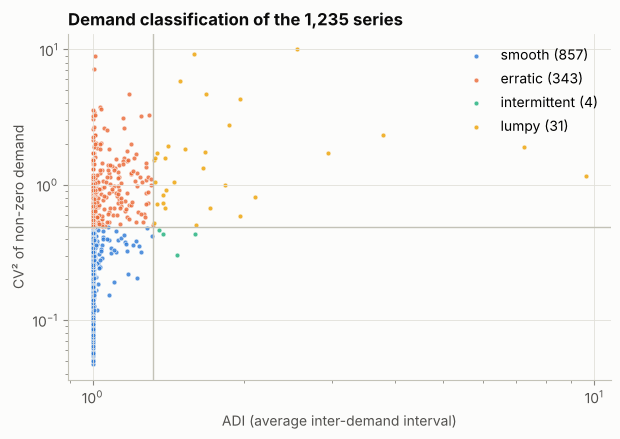

In [15]:
s0 = full.assign(sale_qty=full.sale_qty.fillna(0))
def adi_cv2(s):
    nz = s[s > 0]
    return pd.Series({"ADI": len(s) / max(len(nz), 1), "CV2": (nz.std() / nz.mean()) ** 2 if len(nz) > 1 else np.nan})
dclass = s0.groupby("product_id").sale_qty.apply(adi_cv2).unstack()
dclass["class"] = np.select([(dclass.ADI < 1.32) & (dclass.CV2 < 0.49), dclass.ADI < 1.32, dclass.CV2 < 0.49],
                            ["smooth", "erratic", "intermittent"], "lumpy")
meta["demand_class"] = dclass["class"]
print(dclass["class"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
for i, c in enumerate(["smooth", "erratic", "intermittent", "lumpy"]):
    sub = dclass[dclass["class"] == c]
    ax.scatter(sub.ADI, sub.CV2, s=12, color=PALETTE[i], label=f"{c} ({len(sub)})", alpha=0.8, edgecolor=SURFACE, linewidth=0.5)
ax.axvline(1.32, color=AXIS, lw=1); ax.axhline(0.49, color=AXIS, lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("ADI (average inter-demand interval)"); ax.set_ylabel("CV² of non-zero demand")
ax.set_title("Demand classification of the 1,235 series"); ax.legend()
plt.show()

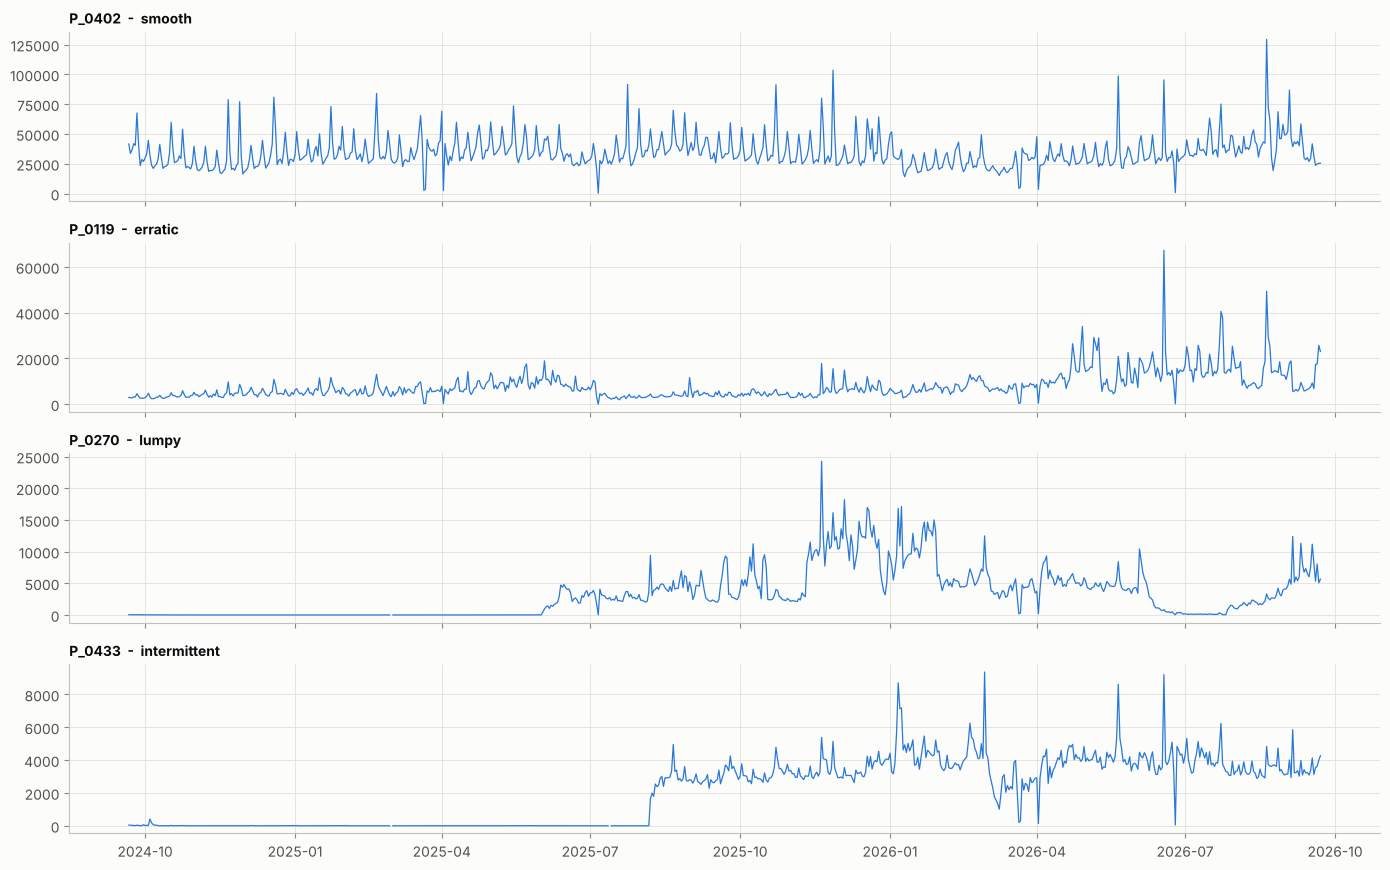

In [16]:
examples = {"smooth": tot_by_prod.index[0]}
for c in ["erratic", "lumpy", "intermittent"]:
    cand = dclass.index[dclass["class"] == c]
    if len(cand): examples[c] = tot_by_prod.reindex(cand).idxmax()
fig, axes = plt.subplots(len(examples), 1, figsize=(14, 2.2 * len(examples)), sharex=True)
for ax, (c, p) in zip(axes, examples.items()):
    s = full[full.product_id == p]
    ax.plot(s.ds, s.sale_qty, color=C_BLUE, lw=0.9)
    ax.set_title(f"{p}  -  {c}", fontsize=10)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

- Most series are **smooth or erratic**, with very few intermittent ones. Dense channel-wise models such as iTransformer and ModernTCN are a good fit; no special intermittent-demand model is needed.

### 5.5 Price: strong inflation

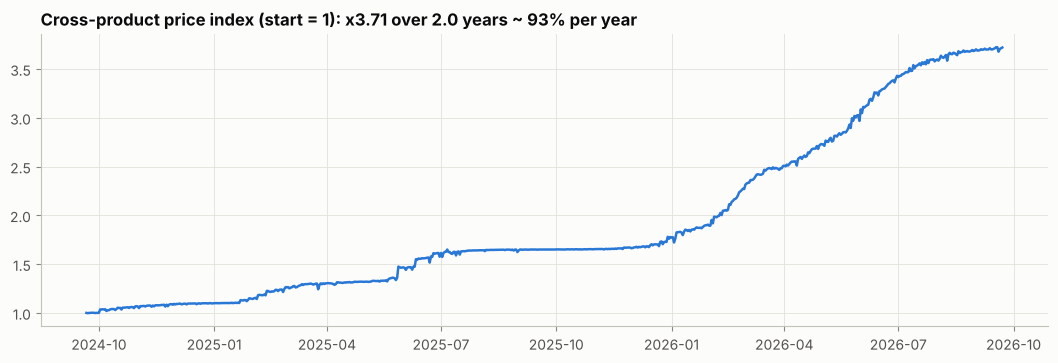

In [17]:
p = df.loc[df.price > 0, ["product_id", "ds", "price"]]
p["rel"] = np.log(p.price) - np.log(p.groupby("product_id").price.transform("median"))
price_index = np.exp(p.groupby("ds").rel.median())
price_index = price_index / price_index.iloc[:7].mean()
years = (price_index.index[-1] - price_index.index[0]).days / 365.25
cagr = (price_index.iloc[-7:].mean()) ** (1 / years) - 1

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(price_index.index, price_index.values, color=C_BLUE, lw=1.8)
ax.set_title(f"Cross-product price index (start = 1): x{price_index.iloc[-7:].mean():.2f} over {years:.1f} years ~ {cagr:.0%} per year")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.show()

- Nominal prices rose about **3.7×** over two years, with inflation accelerating in 2026. Raw price is **non-stationary**, so it must not be fed to the model as-is. Section 8 uses `price_rel` = price / product's **trailing** 28-day median price. It is scale-free, captures price changes, and uses no future information.

### 5.6 Discount, availability and sales

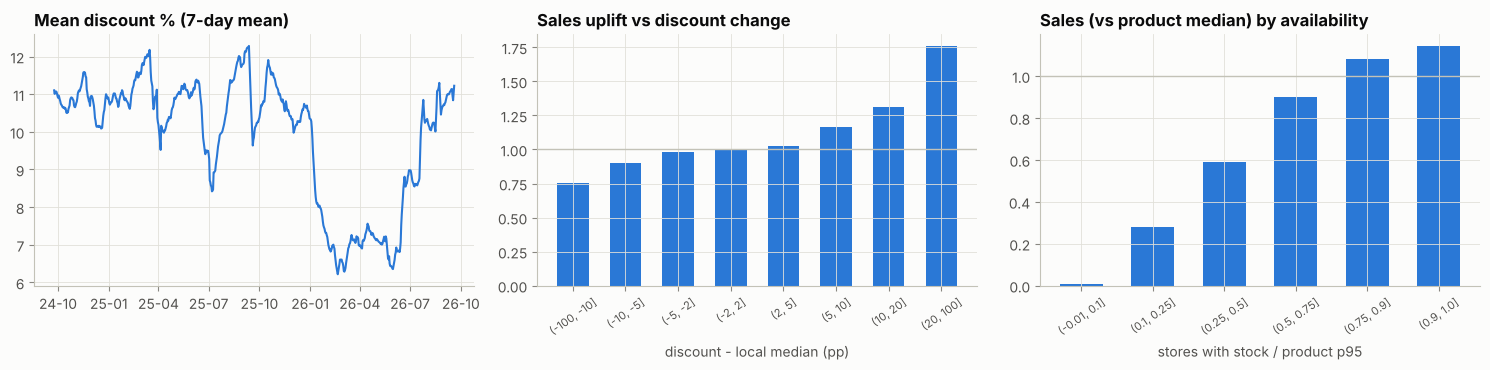

Discount range: 0.0..82.2%  | rows > 50%: 469
Zero-sales days with <= 5 stores stocked: 71%


In [18]:
o = obs[~obs.ds.isin(GLITCH_DATES)].copy()
gb = o.groupby("product_id")
o["sales_ratio"] = o.sale_qty / gb.sale_qty.transform(lambda s: s.rolling(ROLL_WINDOW, center=True, min_periods=7).median()).replace(0, np.nan)
o["disc_dev"] = o.discount_pct - gb.discount_pct.transform(lambda s: s.rolling(ROLL_WINDOW, center=True, min_periods=7).median())
o["sales_vs_typical"] = o.sale_qty / gb.sale_qty.transform("median").replace(0, np.nan)
o["avail"] = o.num_stores_with_stock / gb.num_stores_with_stock.transform(lambda s: s.quantile(0.95)).replace(0, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
dm = df.groupby("ds").discount_pct.mean()
axes[0].plot(dm.index, dm.rolling(7, center=True).mean(), color=C_BLUE)
axes[0].set_title("Mean discount % (7-day mean)"); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%y-%m"))
b = pd.cut(o.disc_dev, [-100, -10, -5, -2, 2, 5, 10, 20, 100])
u = o.groupby(b, observed=True).sales_ratio.median()
axes[1].bar(range(len(u)), u.values, color=C_BLUE, width=0.6)
axes[1].set_xticks(range(len(u)), [str(i) for i in u.index], rotation=35, fontsize=8)
axes[1].axhline(1, color=AXIS, lw=1)
axes[1].set_title("Sales uplift vs discount change"); axes[1].set_xlabel("discount - local median (pp)")
b2 = pd.cut(o.avail.clip(0, 1), [-0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0])
u2 = o.groupby(b2, observed=True).sales_vs_typical.median()
axes[2].bar(range(len(u2)), u2.values, color=C_BLUE, width=0.6)
axes[2].set_xticks(range(len(u2)), [str(i) for i in u2.index], rotation=35, fontsize=8)
axes[2].axhline(1, color=AXIS, lw=1)
axes[2].set_title("Sales (vs product median) by availability"); axes[2].set_xlabel("stores with stock / product p95")
plt.tight_layout(); plt.show()
print(f"Discount range: {df.discount_pct.min()}..{df.discount_pct.max()}%  | rows > 50%: {(df.discount_pct > 50).sum()}")
print(f"Zero-sales days with <= 5 stores stocked: {(df.loc[df.sale_qty == 0, 'num_stores_with_stock'] <= 5).mean():.0%}")

- The **discount regime changed**: average discount fell from about 11% to about 7% in Jan–Jun 2026, then recovered. Discount jumps produce a clear, monotonic **sales uplift**, so extreme discounts (up to 82%) are real promotions and clearances. They are **kept** and used as a covariate.
- Sales scale with **availability**. Most zero-sales days happen when the product is in very few stores, so zeros there are mostly **censored demand (stockouts)**, not lack of interest. They are flagged so the model, or its loss, can account for them.

### 5.7 Within-product correlations and autocorrelation

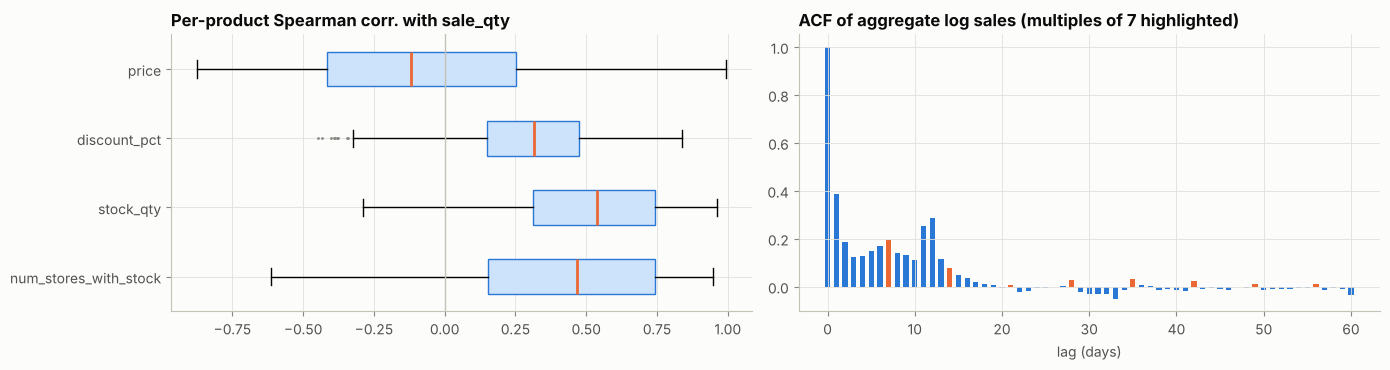

Median per-product ACF of log1p(sales): {'lag1': 0.69, 'lag7': 0.52, 'lag14': 0.39, 'lag28': 0.27}
{'num_stores_with_stock': 0.47, 'stock_qty': 0.54, 'discount_pct': 0.32, 'price': -0.12}


In [19]:
cols = ["sale_qty", "num_stores_with_stock", "stock_qty", "discount_pct", "price"]
cm = o.groupby("product_id")[cols].corr(method="spearman").xs("sale_qty", level=1)[cols[1:]]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
bp = axes[0].boxplot([cm[c].dropna() for c in cm.columns], orientation="horizontal", widths=0.5, patch_artist=True,
                     medianprops=dict(color=C_ORANGE, lw=2), flierprops=dict(marker=".", markersize=2, markeredgecolor=MUTED))
for patch in bp["boxes"]: patch.set(facecolor="#cde2fb", edgecolor=C_BLUE)
axes[0].set_yticks(range(1, len(cm.columns) + 1), cm.columns)
axes[0].axvline(0, color=AXIS, lw=1)
axes[0].set_title("Per-product Spearman corr. with sale_qty")

agg_log = np.log1p(total[~total.index.isin(GLITCH_DATES)].reindex(total.index).interpolate())
r = acf(agg_log, nlags=60)
axes[1].bar(range(len(r)), r, color=[C_ORANGE if k % 7 == 0 and k else C_BLUE for k in range(len(r))], width=0.6)
axes[1].set_title("ACF of aggregate log sales (multiples of 7 highlighted)")
axes[1].set_xlabel("lag (days)")
plt.tight_layout(); plt.show()

lag_acf = pd.DataFrame([acf(np.log1p(s.values), nlags=28)[[1, 7, 14, 28]] for _, s in s0.groupby("product_id").sale_qty],
                       columns=["lag1", "lag7", "lag14", "lag28"])
print("Median per-product ACF of log1p(sales):", lag_acf.median().round(2).to_dict())
print(cm.median().round(2).to_dict())

- Within a product, sales move most strongly with **stock and store availability** (median ρ ≈ 0.5) and positively with **discount** (≈ 0.3). The correlation with raw **price** is only weakly negative (≈ −0.1): inflation drifts every price upward and hides the real price response, so the model gets *relative* price instead.
- Autocorrelation is strong and persistent, with a **weekly (lag-7) cycle**. A look-back of **96 days** (the iTransformer/ModernTCN default) covers about 13 weekly cycles and is a reasonable starting point.

## 6. Handling missing values

| Problem | Evidence (Section 4) | Treatment | Flag |
|---|---|---|---|
| Missing rows inside a product's lifespan (1,499) | follow near-stockouts; Ashura 2026 dropped zero-sales rows | `sale_qty = 0`; other fields imputed as below | `is_missing_row` |
| `stock_qty`, `num_stores_with_stock` on 6 corrupted dates | stock overwritten by sales, stores collapse | set to NaN → **linear interpolation within product** | `is_glitch_day` |
| `price == 0` (= no sale) and price on missing rows | price is a realised price | NaN → **log-linear interpolation within product** (follows inflation), edges ffill/bfill | `price_observed` |
| `discount_pct` on missing rows | promotions are step-like | forward-fill, then back-fill | `is_missing_row` |
| Days before launch / after delisting | 3 products | not imputed in long format; set to 0 and masked in the model tensor | `mask_outside_life` |

In [20]:
clean = full.copy()
clean["is_glitch_day"] = clean.ds.isin(GLITCH_DATES)
clean["price_observed"] = clean.price > 0                      # False for price == 0 and for missing rows

clean.loc[clean.is_glitch_day, ["stock_qty", "num_stores_with_stock"]] = np.nan
clean.loc[~clean.price_observed, "price"] = np.nan
clean["sale_qty"] = clean.sale_qty.fillna(0.0)

g = clean.groupby("product_id", sort=False)
for c in ["stock_qty", "num_stores_with_stock"]:
    clean[c] = g[c].transform(lambda s: s.interpolate(limit_area="inside").ffill().bfill())
clean["price"] = np.exp(g["price"].transform(lambda s: np.log(s).interpolate(limit_area="inside").ffill().bfill()))
clean["discount_pct"] = g["discount_pct"].transform(lambda s: s.ffill().bfill())

print("Remaining NaNs:", clean[NUM].isna().sum().to_dict())
assert clean[NUM].notna().all().all()

Remaining NaNs: {'sale_qty': 0, 'stock_qty': 0, 'num_stores_with_stock': 0, 'discount_pct': 0, 'price': 0}


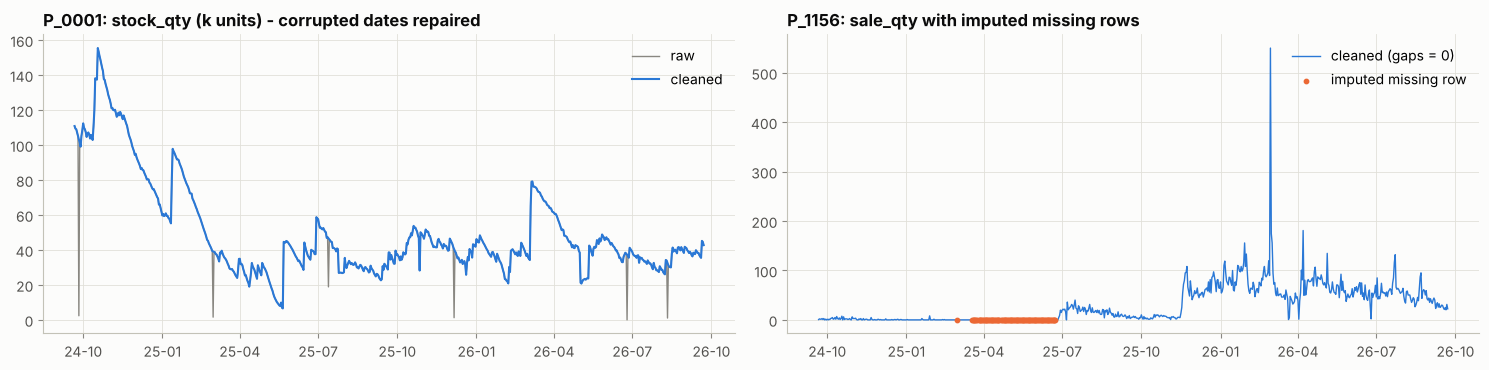

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
p1 = "P_0001"
before, after = full[full.product_id == p1].set_index("ds"), clean[clean.product_id == p1].set_index("ds")
axes[0].plot(before.index, before.stock_qty / 1e3, color=MUTED, lw=1, label="raw")
axes[0].plot(after.index, after.stock_qty / 1e3, color=C_BLUE, lw=1.5, label="cleaned")
axes[0].set_title(f"{p1}: stock_qty (k units) - corrupted dates repaired"); axes[0].legend()
p2 = full.groupby("product_id").is_missing_row.sum().drop(["P_0064", "P_0666"]).idxmax()
before, after = full[full.product_id == p2].set_index("ds"), clean[clean.product_id == p2].set_index("ds")
axes[1].plot(after.index, after.sale_qty, color=C_BLUE, lw=1, label="cleaned (gaps = 0)")
miss = after.index[after.is_missing_row]
axes[1].scatter(miss, np.zeros(len(miss)), color=C_ORANGE, s=10, zorder=3, label="imputed missing row")
axes[1].set_title(f"{p2}: sale_qty with imputed missing rows"); axes[1].legend()
for ax in axes: ax.xaxis.set_major_formatter(mdates.DateFormatter("%y-%m"))
plt.tight_layout(); plt.show()

## 7. Handling outliers

Extreme values fall into three groups, each handled differently:

| Type | Example | Action |
|---|---|---|
| **Data errors** | corrupted stock dates (done in §6); realised price jumps on 1–4 unit days | fix |
| **Real, explainable extremes** | Nowruz/Ashura drops, the 2026-02-28 market surge, promotions, restocks, stockouts | **keep**; encode as features or flags |
| **Unexplained product-level spikes** | one product sells 50× its normal level for a day, with no promo and no market event | **cap** (winsorise), keep the raw value and a flag |

### 7.1 Price outliers

Price outliers: 205 rows (0.023%)  |  median units sold on those days: 1.38


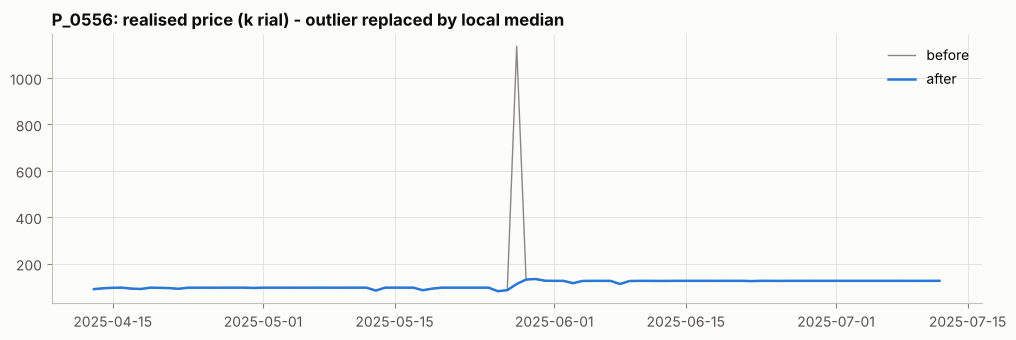

In [22]:
p_obs = clean.price.where(clean.price_observed)
p_med = p_obs.groupby(clean.product_id).transform(lambda s: s.rolling(ROLL_WINDOW, center=True, min_periods=3).median())
ratio = p_obs / p_med
clean["is_price_outlier"] = (ratio < PRICE_BOUNDS[0]) | (ratio > PRICE_BOUNDS[1])
print(f"Price outliers: {clean.is_price_outlier.sum()} rows ({clean.is_price_outlier.mean():.3%})  |  "
      f"median units sold on those days: {clean.loc[clean.is_price_outlier, 'sale_qty'].median():.2f}")
ex = clean.loc[clean.is_price_outlier].assign(r=ratio).sort_values("r").iloc[-1]
win = clean[(clean.product_id == ex.product_id) & (clean.ds.between(ex.ds - pd.Timedelta(days=45), ex.ds + pd.Timedelta(days=45)))]
clean.loc[clean.is_price_outlier, "price"] = p_med[clean.is_price_outlier]
win2 = clean.loc[win.index]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(win.ds, win.price / 1e3, color=MUTED, lw=1, label="before")
ax.plot(win2.ds, win2.price / 1e3, color=C_BLUE, lw=1.8, label="after")
ax.set_title(f"{ex.product_id}: realised price (k rial) - outlier replaced by local median"); ax.legend()
plt.show()

These are realised-price artefacts on days with only a few units sold (an average over 1–4 transactions). They are replaced by the local median price.

### 7.2 Sales spikes: market-adjusted Hampel filter
For every product and day:
1. `resid` = `log1p(sales)` − product's centred 29-day rolling median.
2. `idio` = `resid` − **market effect** (median `resid` of all products in the same Level1 on that day). This removes holidays, weekdays and market-wide events.
3. `z` = `idio` / (1.4826 · MAD of the product's `idio`), with the MAD floored at 0.25.
4. **Flag** when the value is extreme **both** against the market-adjusted expectation (`z > 6`, ≥ 3× expected) **and** against the product's own baseline. This means a product that simply held steady on a holiday is never flagged. The product must also have been actively selling (local median ≥ 1 unit), and there must have been *no* discount jump > 5 pp.

Flagged values are capped at `expm1(base + max(market, 0) + 6·MAD)`, so a holiday never pulls the cap down. The original value is kept in `sale_qty_raw`.

In [23]:
clean["sale_qty_raw"] = clean["sale_qty"]
y, base, resid, market = robust_deviation(clean)
idio = resid - market
mad = np.maximum(idio.abs().groupby(clean.product_id).transform("median") * 1.4826, 0.25)
z = idio / mad
disc_base = clean.groupby("product_id").discount_pct.transform(lambda s: s.rolling(ROLL_WINDOW, center=True, min_periods=3).median())
is_promo = (clean.discount_pct - disc_base) > PROMO_PP
active = np.expm1(base) >= 1

def spike_mask(k):
    return ((z > k) & (resid / mad > k) & (idio > np.log(MIN_SPIKE_MULT)) & (resid > np.log(MIN_SPIKE_MULT))
            & active & ~is_promo & (clean.sale_qty > 0))

sens = pd.DataFrame([{"k": k, "rows flagged": int(spike_mask(k).sum()), "products": clean.product_id[spike_mask(k)].nunique(),
                      "% of total units": round(clean.sale_qty[spike_mask(k)].sum() / clean.sale_qty.sum() * 100, 3)}
                     for k in [4, 5, 6, 8]]).set_index("k")
display(sens)
spikes_promo = ((z > HAMPEL_K) & (resid / mad > HAMPEL_K) & active & is_promo).sum()
print(f"Spikes with z > {HAMPEL_K} explained by a discount jump (kept): {spikes_promo}")

flag = spike_mask(HAMPEL_K)
cap = np.expm1(base + market.clip(lower=0) + HAMPEL_K * mad)   # holidays never lower the cap
clean["is_sales_outlier"] = flag
clean.loc[flag, "sale_qty"] = np.minimum(clean.loc[flag, "sale_qty"], cap[flag])
print(f"Capped {flag.sum()} rows in {clean.product_id[flag].nunique()} products; "
      f"total units changed by {(clean.sale_qty.sum() / clean.sale_qty_raw.sum() - 1):.2%}")
print("Flags on Nowruz / Sizdah / Ashura dates:",
      int(flag[clean.ds.isin(pd.to_datetime(["2025-03-21", "2025-03-22", "2025-04-02", "2025-07-06", "2026-03-21", "2026-03-22", "2026-04-02", "2026-06-25"]))].sum()))

,rows flagged,products,% of total units
k,,,
4,1675,505,0.529
5,1002,354,0.359
6,527,227,0.227
8,181,86,0.103


Spikes with z > 6.0 explained by a discount jump (kept): 350
Capped 527 rows in 227 products; total units changed by -0.09%
Flags on Nowruz / Sizdah / Ashura dates: 0


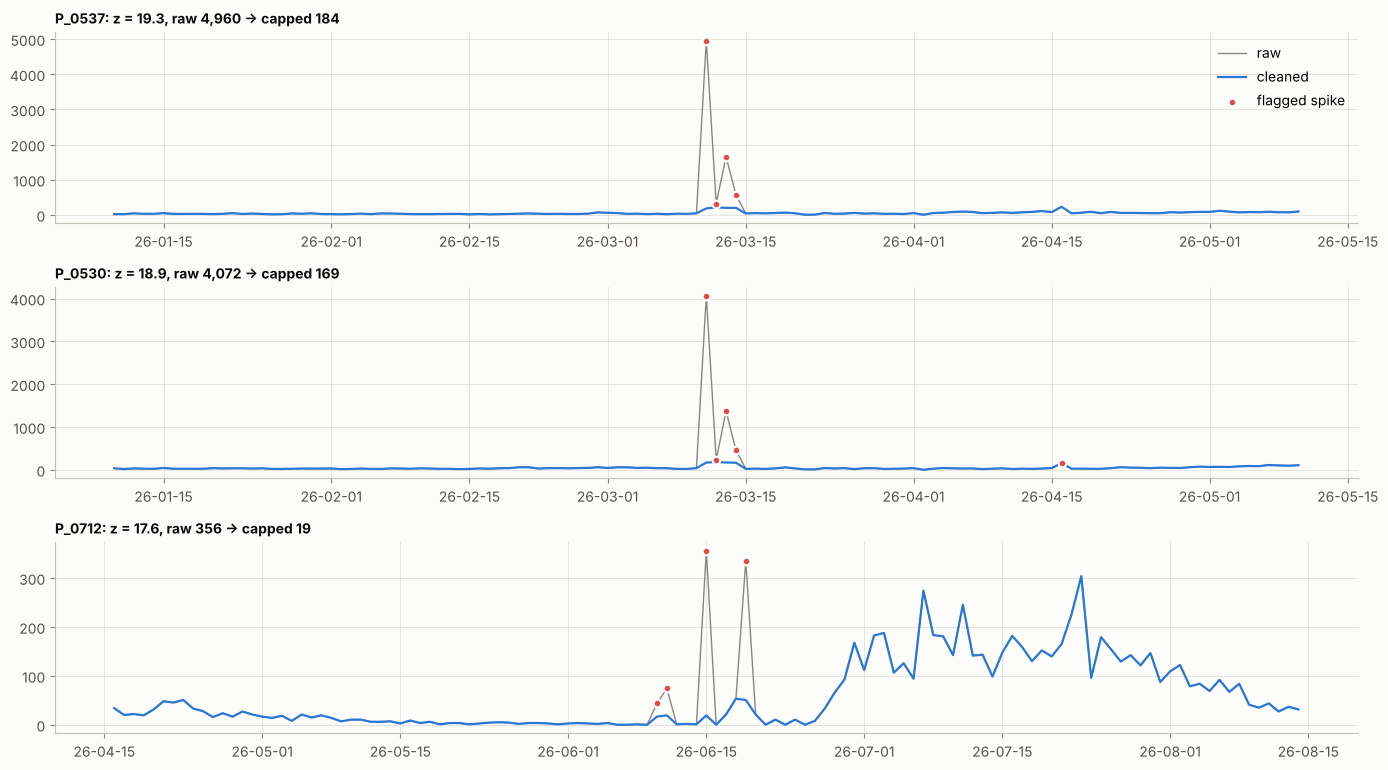

In [24]:
top = clean.assign(z=z)[flag].sort_values("z", ascending=False).drop_duplicates("product_id").head(3)
fig, axes = plt.subplots(len(top), 1, figsize=(14, 2.6 * len(top)))
for ax, (_, row) in zip(axes, top.iterrows()):
    w = clean[(clean.product_id == row.product_id) & clean.ds.between(row.ds - pd.Timedelta(days=60), row.ds + pd.Timedelta(days=60))]
    ax.plot(w.ds, w.sale_qty_raw, color=MUTED, lw=1, label="raw")
    ax.plot(w.ds, w.sale_qty, color=C_BLUE, lw=1.6, label="cleaned")
    f = w[w.is_sales_outlier]
    ax.scatter(f.ds, f.sale_qty_raw, color=C_RED, s=30, zorder=3, label="flagged spike", edgecolor=SURFACE, linewidth=1.5)
    ax.set_title(f"{row.product_id}: z = {row.z:.1f}, raw {row.sale_qty_raw:,.0f} -> capped {row.sale_qty:,.0f}", fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%y-%m-%d"))
axes[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

- Only about **0.06% of rows** (about 0.2% of volume) are capped, so the filter is conservative. Holidays (0 flags, checked above), the market-wide surge and promotion-driven spikes are untouched by design.
- `HAMPEL_K` is a single switch. Set it to `np.inf` to disable capping, or lower it for more aggressive cleaning.

### 7.3 Other variables

In [25]:
clean["is_stockout"] = clean.num_stores_with_stock < 0.5
sm = clean.groupby("product_id").stock_qty.transform(lambda s: s.rolling(ROLL_WINDOW, center=True, min_periods=3).median())
print(f"discount_pct within [0, 100]          : {clean.discount_pct.between(0, 100).all()}  -> kept as is (real promotions)")
print(f"stock_qty > 5x local median (restocks) : {(clean.stock_qty > 5 * sm).sum()} rows -> kept (replenishment), use log1p")
print(f"stock-out days (0 stores with stock)   : {clean.is_stockout.sum():,} rows ({clean.is_stockout.mean():.2%}) -> flagged (censored demand)")

discount_pct within [0, 100]          : True  -> kept as is (real promotions)
stock_qty > 5x local median (restocks) : 258 rows -> kept (replenishment), use log1p
stock-out days (0 stores with stock)   : 3,120 rows (0.35%) -> flagged (censored demand)


## 8. Model-ready data for iTransformer / ModernTCN

Both models consume a **dense multivariate matrix `[T, N]`** (time × variates) and are trained on sliding windows `x: [seq_len, N] → y: [pred_len, N]`.
- **iTransformer** embeds each variate's whole look-back window as one token. Here N = 1,235 products are the tokens, and extra covariates can be added as more tokens.
- **ModernTCN** applies large-kernel depth-wise convolutions along time, per variate, plus cross-variate mixing.

Preparation:
1. **Wide target matrix** of cleaned `sale_qty` (1,235 channels). Days outside a product's lifespan are set to 0 and masked.
2. **`log1p` → per-channel z-score**, with mean/std fitted on the **training period only** (no leakage).
3. **Chronological split 70/10/20** with Time-Series-Library borders. Val and test windows reuse the previous `seq_len` days as context.
4. **Calendar time marks (`x_mark`)** based on the Jalali calendar and Iranian holidays, scaled to [-0.5, 0.5] like TSLib's `timeenc=1`.
5. Optional **exogenous covariates** (discount, availability, relative price) as extra channels for iTransformer's variate tokens.

In [26]:
products = sorted(clean.product_id.unique())
dates = pd.DatetimeIndex(cal.ds)
T, N = len(dates), len(products)

def to_wide(col):
    return clean.pivot(index="ds", columns="product_id", values=col).reindex(index=dates, columns=products)

sales_wide = to_wide("sale_qty")
mask_outside = sales_wide.isna()                          # before launch / after delisting
sales_wide = sales_wide.fillna(0.0)
sales_raw_wide = to_wide("sale_qty_raw").fillna(0.0)
stockout_wide = to_wide("is_stockout").fillna(True).astype(bool)

# chronological split (identical to Time-Series-Library Dataset_Custom)
n_train, n_test = int(T * SPLIT[0]), int(T * SPLIT[2])
n_val = T - n_train - n_test
borders = {"train": (0, n_train), "val": (n_train - SEQ_LEN, n_train + n_val), "test": (T - n_test - SEQ_LEN, T)}
for k, (a, b) in borders.items():
    print(f"{k:5s}: rows {a:3d}-{b - 1:3d}  {dates[a].date()} -> {dates[b - 1].date()}  ({b - a - SEQ_LEN - PRED_LEN + 1} windows)")

# log1p + per-channel standardisation, fitted on train only
Y = np.log1p(sales_wide.values)
mu = Y[:n_train].mean(axis=0)
sd = Y[:n_train].std(axis=0)
sd[sd < 1e-6] = 1.0
Z = ((Y - mu) / sd).astype("float32")
print(f"\nScaled train mean/std: {Z[:n_train].mean():.3f} / {Z[:n_train].std():.3f}  |  "
      f"test mean/std: {Z[-n_test:].mean():.3f} / {Z[-n_test:].std():.3f}")

train: rows   0-511  2024-09-21 -> 2026-02-14  (389 windows)
val  : rows 416-585  2025-11-11 -> 2026-04-29  (47 windows)
test : rows 490-731  2026-01-24 -> 2026-09-22  (119 windows)

Scaled train mean/std: 0.000 / 1.000  |  test mean/std: -0.433 / 1.816


In [27]:
# ---------------- calendar time marks (known in advance for any horizon) ----------------
nowruz = pd.DatetimeIndex([pd.Timestamp(*jalali_to_gregorian(y, 1, 1)) for y in range(cal.j_year.min() + 1, cal.j_year.max() + 2)])
next_nowruz = nowruz[np.searchsorted(nowruz, dates)]
FIXED_SOLAR_HOLIDAYS = {(1, 1), (1, 2), (1, 3), (1, 4), (1, 12), (1, 13), (3, 14), (3, 15), (11, 22), (12, 29)}
# Lunar (Hijri) holidays move ~11 days/year. Tasua/Ashura are verified against the data above.
# Extend this list from the official Iranian calendar for the forecast horizon.
LUNAR_HOLIDAYS = pd.to_datetime(["2025-07-05", "2025-07-06", "2026-06-24", "2026-06-25"])

jm, jd = cal.j_month.values, cal.j_day.values
j_doy = np.where(jm <= 6, (jm - 1) * 31, 186 + (jm - 7) * 30) + jd
marks = pd.DataFrame({
    "day_of_week":    ((dates.day_of_week + 2) % 7) / 6 - 0.5,        # Saturday = 0 (Iranian week)
    "jalali_day":     (jd - 1) / 30 - 0.5,
    "jalali_month":   (jm - 1) / 11 - 0.5,
    "jalali_doy":     (j_doy - 1) / 365 - 0.5,
    "days_to_nowruz": np.clip((next_nowruz - dates).days, 0, 30) / 30 - 0.5,
    "is_nowruz":      np.isin(list(zip(jm, jd)), [list(t) for t in FIXED_SOLAR_HOLIDAYS if t[0] == 1 and t[1] <= 4]).all(axis=1).astype(float) - 0.5,
    "is_holiday":     (np.array([(m, d) in FIXED_SOLAR_HOLIDAYS for m, d in zip(jm, jd)]) | dates.isin(LUNAR_HOLIDAYS)).astype(float) - 0.5,
}, index=dates)
x_mark = marks.values.astype("float32")
print("x_mark:", x_mark.shape, list(marks.columns))
print("Holidays in data range:", [str(d.date()) for d in dates[marks.is_holiday > 0]])

# ---------------- optional exogenous covariates (no look-ahead) ----------------
disc_wide = (to_wide("discount_pct").ffill().fillna(0.0) / 100).astype("float32")
stores_wide = to_wide("num_stores_with_stock").fillna(0.0)
avail_wide = (stores_wide / stores_wide.iloc[:n_train].quantile(0.95).replace(0, 1)).clip(0, 1).astype("float32")
price_wide = to_wide("price").ffill().bfill()
price_rel_wide = np.log(price_wide / price_wide.rolling(28, min_periods=1).median()).astype("float32")  # trailing window

x_mark: (732, 7) ['day_of_week', 'jalali_day', 'jalali_month', 'jalali_doy', 'days_to_nowruz', 'is_nowruz', 'is_holiday']
Holidays in data range: ['2025-02-10', '2025-03-19', '2025-03-21', '2025-03-22', '2025-03-23', '2025-03-24', '2025-04-01', '2025-04-02', '2025-06-04', '2025-06-05', '2025-07-05', '2025-07-06', '2026-02-11', '2026-03-20', '2026-03-21', '2026-03-22', '2026-03-23', '2026-03-24', '2026-04-01', '2026-04-02', '2026-06-04', '2026-06-05', '2026-06-24', '2026-06-25']


train:  389 windows | seq_x (96, 1235) seq_y (76, 1235) x_mark (96, 7) y_mark (76, 7)
val  :   47 windows | seq_x (96, 1235) seq_y (76, 1235) x_mark (96, 7) y_mark (76, 7)
test :  119 windows | seq_x (96, 1235) seq_y (76, 1235) x_mark (96, 7) y_mark (76, 7)


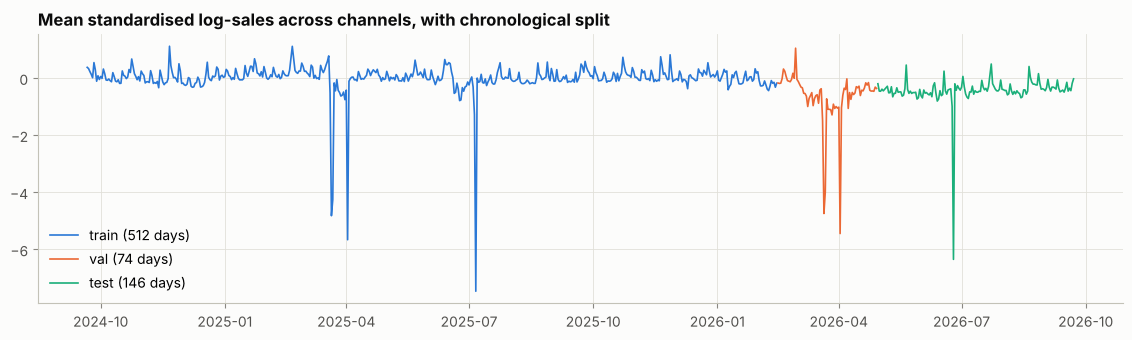

In [28]:
class WindowDataset:
    # Numpy sliding-window dataset with the Time-Series-Library interface: (seq_x, seq_y, seq_x_mark, seq_y_mark).
    # Can be wrapped directly by torch.utils.data.DataLoader.
    def __init__(self, data, marks, border, seq_len=SEQ_LEN, label_len=LABEL_LEN, pred_len=PRED_LEN):
        a, b = border
        self.x, self.m = data[a:b], marks[a:b]
        self.seq_len, self.label_len, self.pred_len = seq_len, label_len, pred_len
    def __len__(self):
        return len(self.x) - self.seq_len - self.pred_len + 1
    def __getitem__(self, i):
        s_end = i + self.seq_len
        r_begin, r_end = s_end - self.label_len, s_end + self.pred_len
        return self.x[i:s_end], self.x[r_begin:r_end], self.m[i:s_end], self.m[r_begin:r_end]

for split, border in borders.items():
    ds_ = WindowDataset(Z, x_mark, border)
    sx, sy, smx, smy = ds_[0]
    print(f"{split:5s}: {len(ds_):4d} windows | seq_x {sx.shape} seq_y {sy.shape} x_mark {smx.shape} y_mark {smy.shape}")

fig, ax = plt.subplots(figsize=(14, 3.5))
agg = Z.mean(axis=1)
for (name, (a, b)), color in zip([("train", (0, n_train)), ("val", (n_train, n_train + n_val)), ("test", (n_train + n_val, T))],
                                 [C_BLUE, C_ORANGE, C_AQUA]):
    ax.plot(dates[a:b], agg[a:b], color=color, lw=1.2, label=f"{name} ({b - a} days)")
ax.set_title("Mean standardised log-sales across channels, with chronological split"); ax.legend(loc="lower left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.show()

### Export

In [29]:
# 1) Time-Series-Library CSV (date + one column per product), unscaled log1p - let TSLib's scaler (scale=True) standardise
tslib = pd.DataFrame(Y.astype("float32"), index=dates, columns=products)
tslib.index.name = "date"
tslib.to_csv(OUT_DIR / "sales_wide_log1p.csv", float_format="%.6f")

# 2) Pre-scaled tensors + masks + marks + covariates for a custom PyTorch pipeline
np.savez_compressed(
    OUT_DIR / "itransformer_moderntcn_data.npz",
    data=Z, x_mark=x_mark, mean=mu.astype("float32"), std=sd.astype("float32"),
    sales=sales_wide.values.astype("float32"), sales_raw=sales_raw_wide.values.astype("float32"),
    mask_outside_life=mask_outside.values, mask_stockout=stockout_wide.values,
    cov_discount=disc_wide.values, cov_availability=avail_wide.values, cov_price_rel=price_rel_wide.values,
    dates=dates.strftime("%Y-%m-%d").values.astype(str), jdates=cal.jdate.values.astype(str),
    products=np.array(products), mark_names=np.array(marks.columns),
    borders=np.array([borders["train"], borders["val"], borders["test"]]),
    seq_len=SEQ_LEN, label_len=LABEL_LEN, pred_len=PRED_LEN,
)

# 3) Cleaned long panel with every flag (for tree models / auditing) and product metadata
keep = ["product_id", "ds"] + STATIC + ["sale_qty", "sale_qty_raw", "stock_qty", "num_stores_with_stock", "discount_pct", "price",
        "is_missing_row", "is_glitch_day", "price_observed", "is_price_outlier", "is_sales_outlier", "is_stockout"]
clean[keep].merge(cal[["ds", "jdate"]], on="ds").to_parquet(OUT_DIR / "panel_clean.parquet", index=False)
meta.assign(train_log_mean=mu, train_log_std=sd).to_csv(OUT_DIR / "product_meta.csv")

for f in sorted(OUT_DIR.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:6.1f} MB")

itransformer_moderntcn_data.npz            14.9 MB
panel_clean.parquet                        19.2 MB
product_meta.csv                            0.1 MB
sales_wide_log1p.csv                        8.2 MB


**How to use the exports**

*Time-Series-Library (official iTransformer / ModernTCN code):* copy `sales_wide_log1p.csv` into `./dataset/` and run, for example:
```bash
python run.py --task_name long_term_forecast --is_training 1 --model iTransformer \
  --data custom --root_path ./dataset/ --data_path sales_wide_log1p.csv \
  --features M --target P_0001 --freq d --seq_len 96 --label_len 48 --pred_len 28 \
  --enc_in 1235 --dec_in 1235 --c_out 1235
```
TSLib standardises per channel on its own train split (same 70/10/20 borders as here). Invert predictions with `expm1` after its inverse scaling. Its default time features are Gregorian. To use the Jalali/holiday marks, load `x_mark` from the `.npz` in a custom `Dataset`.

*Custom PyTorch:* load `itransformer_moderntcn_data.npz` and wrap `WindowDataset(Z, x_mark, border)` in a `DataLoader`. To get units back: `np.expm1(pred * std + mean)`.

**Recommendations**
- **Normalisation / distribution shift:** the test period sits lower and is more volatile than train (see the scaled mean/std printed above: 2026 has the Nowruz slump and discontinued products). Keep **RevIN / instance normalisation** on: `--use_norm 1` in iTransformer, `revin=1` in ModernTCN. It complements the global train-fitted scaling.
- **Loss masking:** ignore positions where `mask_outside_life` is set. Optionally down-weight `mask_stockout` days, whose zero sales are censored demand.
- **Evaluation:** report test metrics against `sales_raw` (un-capped) as well as `sales`, so the outlier capping cannot flatter the score.
- **Covariates:** for iTransformer, append `cov_discount`, `cov_availability` and `cov_price_rel` as extra variate tokens (`--enc_in` grows accordingly) and drop them from the output. Use availability with care: future values are only known if you have a replenishment plan.
- **Holidays:** extend `LUNAR_HOLIDAYS` with the official calendar for the forecast horizon. Ashura and Nowruz move sales by up to 99%.

## 9. Summary

In [30]:
summary = {
    "rows (raw)": f"{len(df):,}",
    "products x days": f"{N} x {T} ({dates[0].date()} -> {dates[-1].date()}; Jalali {cal.jdate.iloc[0]} -> {cal.jdate.iloc[-1]})",
    "missing rows imputed (sale_qty=0)": f"{int(clean.is_missing_row.sum()):,}",
    "corrupted dates repaired (stock, stores)": ", ".join(str(d.date()) for d in GLITCH_DATES),
    "price==0 rows treated as missing": f"{int((~clean.price_observed & ~clean.is_missing_row).sum()):,}",
    "price outliers replaced": f"{int(clean.is_price_outlier.sum())}",
    "sales spikes capped": f"{int(clean.is_sales_outlier.sum())} rows ({clean.is_sales_outlier.mean():.2%})",
    "stock-out rows flagged": f"{int(clean.is_stockout.sum()):,}",
    "model tensor": f"{Z.shape} float32, log1p + train-only z-score, x_mark {x_mark.shape}",
}
pd.Series(summary, name="value").to_frame()

,value
rows (raw),"902,438"
products x days,1235 x 732 (2024-09-21 -> 2026-09-22; Jalali 1...
missing rows imputed (sale_qty=0),"1,499"
"corrupted dates repaired (stock, stores)","2024-09-26, 2025-03-01, 2025-07-13, 2025-12-06..."
price==0 rows treated as missing,"22,957"
price outliers replaced,205
sales spikes capped,527 rows (0.06%)
stock-out rows flagged,"3,120"
model tensor,"(732, 1235) float32, log1p + train-only z-scor..."


**Key findings**
1. **Dates are Jalali**: 732 consecutive days, 1403/06/31 → 1405/06/31 (2024-09-21 → 2026-09-22).
2. **There are no explicit NaNs, but there are hidden missing values**: 1,499 missing rows (near-stockouts, plus zero-sales rows dropped on Ashura 2026), `price = 0` on every zero-sales day, and **6 corrupted dates** where stock was overwritten by sales and store counts collapsed.
3. **Strong calendar structure**: a Thursday peak, a pre-Nowruz surge, and near-total closures on Nowruz, Sizdah Bedar and Tasua/Ashura. These are real and are kept as features, not removed as outliers.
4. **Nominal price rose about 3.7× in two years** (inflation), so the model uses relative price, not raw price.
5. Sales are heavy-tailed and product scales span about 5 orders of magnitude, so the model uses `log1p` plus per-channel standardisation fitted on train only.
6. Outlier handling is **conservative and reversible**: only unexplained product-level spikes are capped, and raw values and flags are preserved.